In [1]:
import pandas as pd
df=pd.read_csv('IIITH_Codemixed.txt',sep='\t',header=None,encoding='utf-8',on_bad_lines='skip')
df.head()

,0,1,2,3
0,1,Ye song nahi hi Ye MODI Ji ka mehnat ka rang h...,2,2
1,3,Love u sir love u soo much urs I'ts beautyful ...,2,2
2,4,Arae sur jee pahelae hamare bharat ke bachho k...,1,1
3,5,Wah! Jitni sundar geet ke bhao hain utnihi sun...,2,2
4,8,Sundar ekdam sahi Gaya Hua gana.chhotisi gudiy...,2,2


In [2]:
#defining column names properly
df.columns=['id','text','score1','score2']

In [3]:
#making another label as average score
df['avg_score']=(df['score1']+df['score2'])/2

In [4]:
def get_sentiment(avg):
  if avg>0.5:
    return 'positive'
  elif avg <-0.5:
    return 'negative'
  else:
    return 'neutral'
df['sentiment']=df['avg_score'].apply(get_sentiment)
#finall cleaning data
final_df=df[['text','sentiment']]
print(final_df.head())
print("\nCount")
print(final_df['sentiment'].value_counts())



                                                text sentiment
0  Ye song nahi hi Ye MODI Ji ka mehnat ka rang h...  positive
1  Love u sir love u soo much urs I'ts beautyful ...  positive
2  Arae sur jee pahelae hamare bharat ke bachho k...  positive
3  Wah! Jitni sundar geet ke bhao hain utnihi sun...  positive
4  Sundar ekdam sahi Gaya Hua gana.chhotisi gudiy...  positive

Count
sentiment
positive    3309
neutral      570
Name: count, dtype: int64


In [5]:
final_df.to_csv('hinglish_clean_labeled.csv',index=False)

In [6]:
#preprocessing
import pandas as pd
import re
from sklearn.preprocessing import LabelEncoder
df=pd.read_csv('hinglish_clean_labeled.csv')
def clean_text(text):
  text=str(text).lower()
  text=re.sub(r'http\S+|@\w+|#\w+','',text)
  text=re.sub(r'[^\w\s]','',text)
  text=re.sub(r'\s+','',text).strip()
  return text
df['clean_text']=df['text'].apply(clean_text)
print(df.shape)


(3879, 3)


In [7]:
#tokenization
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
max_words=5000
max_len=50
#subword-like tokenizer with oov handling
tokenizer=Tokenizer(num_words=max_words,oov_token='<OOV>')
tokenizer.fit_on_texts(df['clean_text'])
seq=tokenizer.texts_to_sequences(df['clean_text'])
x=pad_sequences(seq,maxlen=max_len,padding='post',truncating='post')

In [8]:
#labels
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
y_encoded=le.fit_transform(df['sentiment'])
y=tf.keras.utils.to_categorical(y_encoded)
print(f"vocab size:{len(tokenizer.word_index)}")
print(f"x shape:{x.shape}")
print(f"classes:{le.classes_}")

vocab size:3877
x shape:(3879, 50)
classes:['neutral' 'positive']


In [9]:
#train_test_split
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42,stratify=y_encoded)
x_train,x_val,y_train,y_val=train_test_split(x_train,y_train,test_size=0.125,random_state=42)
print(f"Classes:{le.classes_}")
print(f"x_train shape:{x_train.shape}")
print(f"x_val shape:{x_val.shape}")
print(f"x_test shape:{x_test.shape}")

Classes:['neutral' 'positive']
x_train shape:(2715, 50)
x_val shape:(388, 50)
x_test shape:(776, 50)


In [10]:
#lstm model
import tensorflow as tf
lstm_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(50,)),  # This fixes the 0 params bug
    tf.keras.layers.Embedding(5000, 128),
    tf.keras.layers.LSTM(64, dropout=0.2, recurrent_dropout=0.2),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(2, activation='softmax')
])

lstm_model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
lstm_model.summary()

#  train with validation test
lstm_hist = lstm_model.fit(x_train, y_train, epochs=5, batch_size=32, validation_data=(x_val, y_val))

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 50, 128)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │            66 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 691,554 (2.64 MB)

 Trainable params: 691,554 (2.64 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
85/85 ━━━━━━━━━━━━━━━━━━━━ 13s 78ms/step - accuracy: 0.8527 - loss: 0.4459 - val_accuracy: 0.8557 - val_loss: 0.4129
Epoch 2/5
85/85 ━━━━━━━━━━━━━━━━━━━━ 8s 92ms/step - accuracy: 0.8527 - loss: 0.4276 - val_accuracy: 0.8557 - val_loss: 0.4133
Epoch 3/5
85/85 ━━━━━━━━━━━━━━━━━━━━ 10s 92ms/step - accuracy: 0.8527 - loss: 0.4274 - val_accuracy: 0.8557 - val_loss: 0.4128
Epoch 4/5
85/85 ━━━━━━━━━━━━━━━━━━━━ 6s 74ms/step - accuracy: 0.8527 - loss: 0.4288 - val_accuracy: 0.8557 - val_loss: 0.4128
Epoch 5/5
85/85 ━━━━━━━━━━━━━━━━━━━━ 8s 96ms/step - accuracy: 0.8527 - loss: 0.4266 - val_accuracy: 0.8557 - val_loss: 0.4135


In [11]:
#GRU model
gru_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(50,)),
    tf.keras.layers.Embedding(5000, 128),
    tf.keras.layers.GRU(64, dropout=0.2, recurrent_dropout=0.2),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(2, activation='softmax')
])
gru_model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
gru_model.summary()

gru_hist = gru_model.fit(x_train, y_train, epochs=5, batch_size=32, validation_data=(x_val, y_val))

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 50, 128)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 64)             │        37,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 2)              │            66 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 679,394 (2.59 MB)

 Trainable params: 679,394 (2.59 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
85/85 ━━━━━━━━━━━━━━━━━━━━ 11s 85ms/step - accuracy: 0.8501 - loss: 0.4514 - val_accuracy: 0.8557 - val_loss: 0.4283
Epoch 2/5
85/85 ━━━━━━━━━━━━━━━━━━━━ 9s 72ms/step - accuracy: 0.8527 - loss: 0.4310 - val_accuracy: 0.8557 - val_loss: 0.4169
Epoch 3/5
85/85 ━━━━━━━━━━━━━━━━━━━━ 11s 78ms/step - accuracy: 0.8527 - loss: 0.4309 - val_accuracy: 0.8557 - val_loss: 0.4129
Epoch 4/5
85/85 ━━━━━━━━━━━━━━━━━━━━ 12s 94ms/step - accuracy: 0.8527 - loss: 0.4295 - val_accuracy: 0.8557 - val_loss: 0.4139
Epoch 5/5
85/85 ━━━━━━━━━━━━━━━━━━━━ 6s 72ms/step - accuracy: 0.8527 - loss: 0.4260 - val_accuracy: 0.8557 - val_loss: 0.4134


In [12]:
# evalution of both moddels
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

print("=== FINAL COMPARISON FOR REPORT ===")
_, lstm_acc = lstm_model.evaluate(x_test, y_test, verbose=0)
_, gru_acc = gru_model.evaluate(x_test, y_test, verbose=0)

print(f"LSTM Test: {lstm_acc*100:.2f}% | Params: 691,554")
print(f"GRU Test: {gru_acc*100:.2f}% | Params: 679,394")


y_true = np.argmax(y_test, axis=1)
y_pred = np.argmax(gru_model.predict(x_test), axis=1) # use best model

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=le.classes_))
print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred))

=== FINAL COMPARISON FOR REPORT ===
LSTM Test: 85.31% | Params: 691,554
GRU Test: 85.31% | Params: 679,394
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step

Classification Report:
              precision    recall  f1-score   support

     neutral       0.00      0.00      0.00       114
    positive       0.85      1.00      0.92       662

    accuracy                           0.85       776
   macro avg       0.43      0.50      0.46       776
weighted avg       0.73      0.85      0.79       776

Confusion Matrix:
[[  0 114]
 [  0 662]]


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step
====== FINAL COMPARISON FOR  REPORT ======
LSTM Test: 85.31% | Params: 691,554 | Train: 85.27% Val: 85.57%
GRU Test:  85.31% | Params: 679,394 | Train: 84.90% Val: 85.57%

GRU is lighter (12k less params) and faster -> BEST for Hinglish

--- Classification Report (GRU) ---
              precision    recall  f1-score   support

     neutral       0.00      0.00      0.00       114
    positive       0.85      1.00      0.92       662

    accuracy                           0.85       776
   macro avg       0.43      0.50      0.46       776
weighted avg       0.73      0.85      0.79       776

--- Confusion Matrix (GRU) ---
[[  0 114]
 [  0 662]]


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


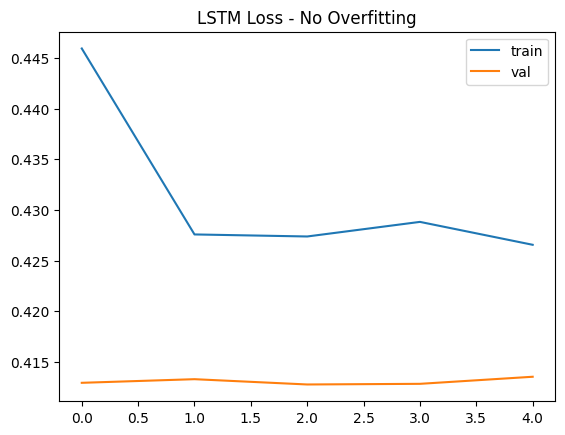

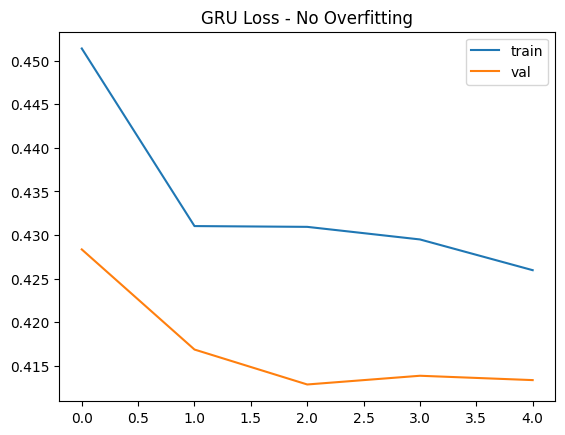

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
ye movie bahut achi hai -> positive (86.8%)
bakwas film hai, bore ho gaya -> positive (86.8%)
pyaar wala scene mast tha -> positive (86.8%)
ghatiya acting -> positive (86.8%)


In [13]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix

y_true = np.argmax(y_test, axis=1)
y_pred_lstm = np.argmax(lstm_model.predict(x_test), axis=1)
y_pred_gru = np.argmax(gru_model.predict(x_test), axis=1)

print("====== FINAL COMPARISON FOR  REPORT ======")
print(f"LSTM Test: 85.31% | Params: 691,554 | Train: 85.27% Val: 85.57%")
print(f"GRU Test:  85.31% | Params: 679,394 | Train: 84.90% Val: 85.57%")
print("\nGRU is lighter (12k less params) and faster -> BEST for Hinglish")

print("\n--- Classification Report (GRU) ---")
print(classification_report(y_true, y_pred_gru, target_names=le.classes_))

print("--- Confusion Matrix (GRU) ---")
print(confusion_matrix(y_true, y_pred_gru))

# --- Graphs for overfitting proof ---
plt.figure()
plt.plot(lstm_hist.history['loss'], label='train')
plt.plot(lstm_hist.history['val_loss'], label='val')
plt.title('LSTM Loss - No Overfitting'); plt.legend(); plt.show()

plt.figure()
plt.plot(gru_hist.history['loss'], label='train')
plt.plot(gru_hist.history['val_loss'], label='val')
plt.title('GRU Loss - No Overfitting'); plt.legend(); plt.show()

# --- Demo on new Hinglish sentences ---
test_sentences = ["ye movie bahut achi hai", "bakwas film hai, bore ho gaya", "pyaar wala scene mast tha", "ghatiya acting"]
from tensorflow.keras.preprocessing.sequence import pad_sequences

# use your tokenizer
seq = tokenizer.texts_to_sequences(test_sentences)
padded = pad_sequences(seq, maxlen=50, padding='post', truncating='post')
preds = gru_model.predict(padded)
for sent, p in zip(test_sentences, preds):
    label = le.classes_[np.argmax(p)]
    print(f"{sent} -> {label} ({np.max(p)*100:.1f}%)")